In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.datasets import load_iris
from scipy.cluster.hierarchy import linkage, dendrogram

In [7]:
# Loading the dataset
iris = load_iris()
X = iris.data
y = iris.target

df = pd.DataFrame(X,columns = iris.feature_names)

print("Shape:", df.shape)
df.head()

Shape: (150, 4)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


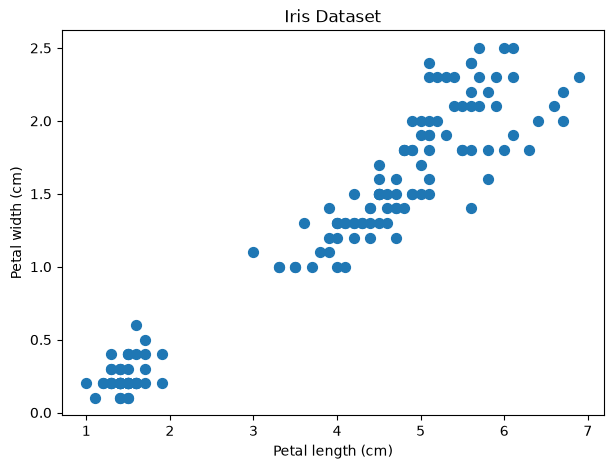

In [10]:
# visualize two features of the real dataset
plt.figure(figsize=(7,5))
plt.scatter(
    X[:,2],
    X[:,3],
    s = 50
)

plt.xlabel("Petal length (cm)")
plt.ylabel("Petal width (cm)")
plt.title("Iris Dataset")
plt.show()



In [11]:
# ## Hierarchical clustering use distances , therefore standardization puts the four features on a comparable scale 

In [12]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

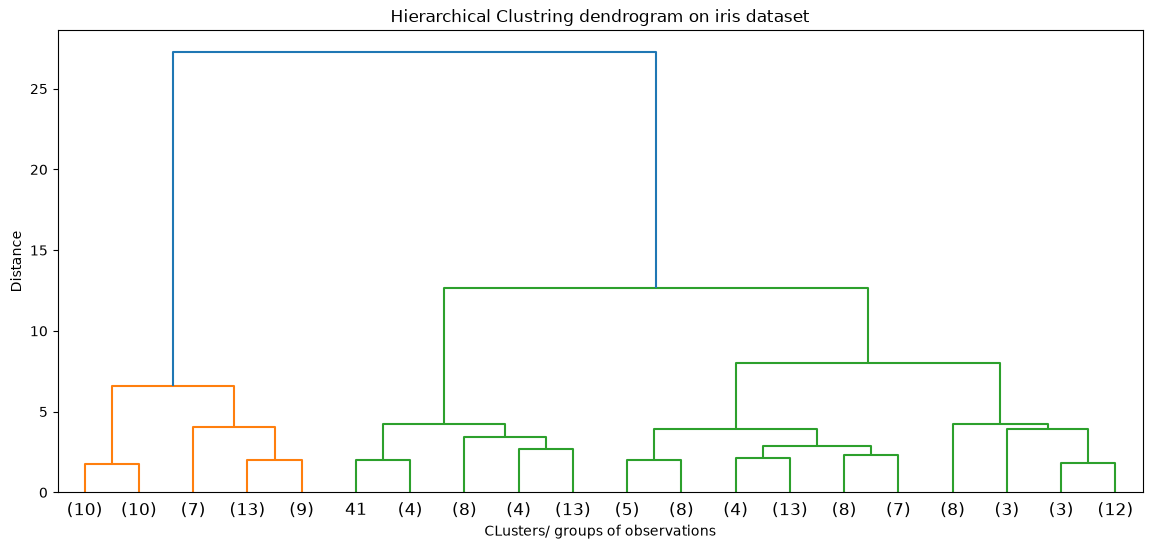

In [16]:
# Create the dendrogram linkage , here we use ward linkage
Z = linkage(X_scaled, method = "ward")
plt.figure(figsize=(14,6))

dendrogram(
    Z,
    truncate_mode = "lastp",
    p = 20,
    show_leaf_counts = True
)


plt.xlabel("CLusters/ groups of observations")
plt.ylabel("Distance")
plt.title("Hierarchical Clustring dendrogram on iris dataset")
plt.show()



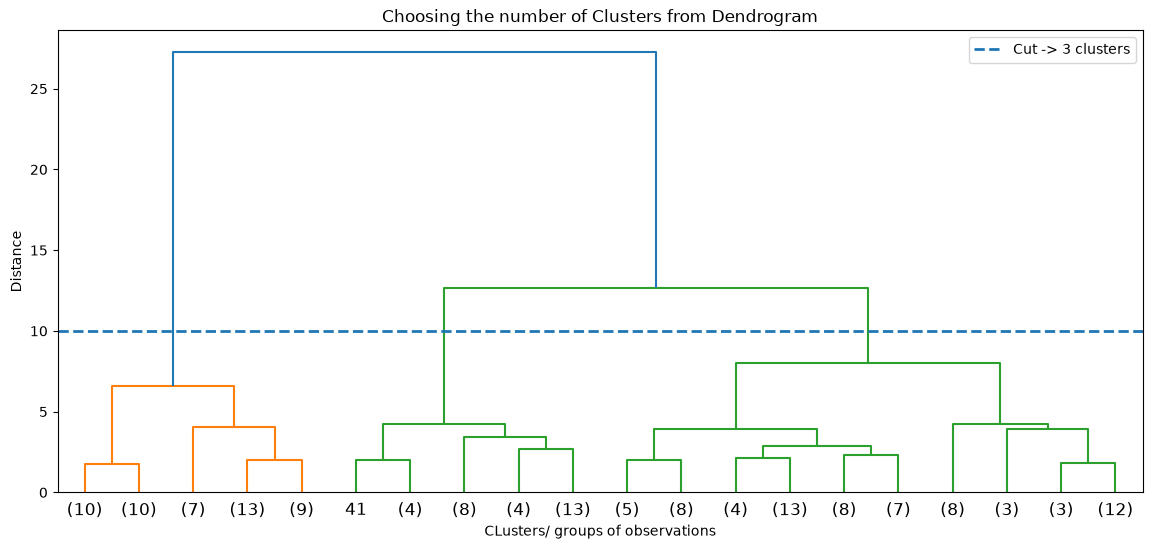

In [18]:
cut_height = 10
plt.figure(figsize = (14,6))

dendrogram(
    Z,
    truncate_mode = "lastp",
    p = 20,
    show_leaf_counts = True
)

plt.axhline(
    y = cut_height,
    linestyle = "--",
    linewidth = 2,
    label = "Cut -> 3 clusters"
)

plt.xlabel("CLusters/ groups of observations")
plt.ylabel("Distance")
plt.title("Choosing the number of Clusters from Dendrogram")
plt.legend()
plt.show()


In [19]:
# Apply agglomerative clustring 
model = AgglomerativeClustering(
    n_clusters = 3,
    linkage = "ward"
)

labels = model.fit_predict(X_scaled)

print("Cluster labels : ")
print(labels)

Cluster labels : 
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 2 1 1 1 1 1 1 1 1 0 0 0 2 0 2 0 2 0 2 2 0 2 0 2 0 2 2 2 2 0 0 0 0
 0 0 0 0 0 2 2 2 2 0 2 0 0 2 2 2 2 0 2 2 2 2 2 0 2 2 0 0 0 0 0 0 2 0 0 0 0
 0 0 0 0 0 0 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0]


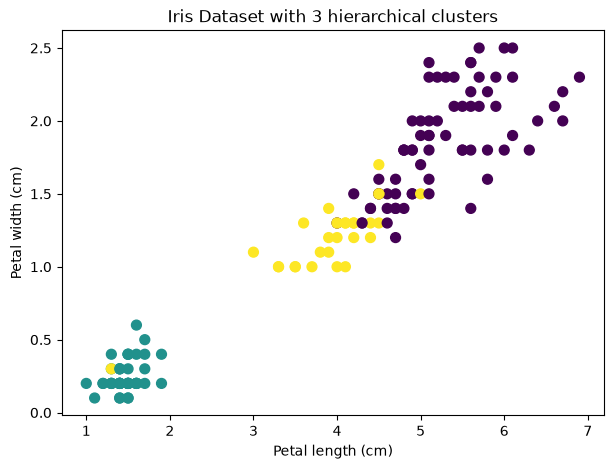

In [20]:
plt.figure(figsize=(7,5))
plt.scatter(
    X[:,2],
    X[:,3],
    s = 50,
    c = labels
)

plt.xlabel("Petal length (cm)")
plt.ylabel("Petal width (cm)")
plt.title("Iris Dataset with 3 hierarchical clusters")
plt.show()



